# AP 155 Lab Exercise
---
## Exercise 9: Interpolation

_Instructions_:
- **Report figures:** Compare the original data with interpolated reconstructions. Include the synthetic sine example and the sampled real-world dataset, if available. For the real-world dataset, compare sampling levels of 50%, 30%, 10%, and 5%.
  
- **Report discussion:** Explain how the choice of interpolator and sampling level affects the reconstruction. Discuss limitations, including behavior outside the sampled domain.
- **Code:** Complete the code and ensure it is functional, readable, and efficient. Include concise Markdown documentation highlighting the critical steps.

### Student Information
- _Full Name (Last Name, First Name)_: INIEGO, Angel Nicole V.
- _Student No._: 2024-09622
- _Section_: THX-TX1

### Grading Information (c/o Lab Instructor)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figures | XX | 20 |
| Report discussion | XX | 20 |
| Code readability | XX | 20 |
| Code efficiency | XX | 20 |
| Code appropriateness | XX | 20 |
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_

---
## Section 1: Report

### Report figures

**Figure 1. Synthetic data interpolation.** 
<img src="../Figures/09_InterpMethods.png" alt="Combined Plots for phi(x) and f(x)." width=100% caption="Combined Plots">

**Figure 2. Real-world data reconstruction.** Insert the four reconstruction plots for sampling levels of 50%, 30%, 10%, and 5%.
<img src="../Figures/09_ConstantCubic_FourSampling.png" alt="Combined Plots for phi(x) and f(x)." width=100% caption="Combined Plots">

<img src="../Figures/09_ConstantSampling_FourMethods.png" alt="Combined Plots for phi(x) and f(x)." width=100% caption="Combined Plots">

### Report discussion

**Interpolator comparison:** The methods differ in how they connecty neighboring samples. Nearest-neighbor assignes eacb point the value of the closest sample, which then produces a discontinuous staircase. This has the largest error. Linear interpolation joins consecutive samples with straight lines, which cuts through the corners at the peaks. Quadratic and cubic interpolation fit piecewise polynomials that follow the curvature of the data, so their reconstructions are smooth and nearly indistinguishable. With that, we use the cubic for the 

**Sampling-level comparison:** As the number of sampled points decreases, the gaps between samples widen and the reconstruction error grows for every method. Higher-order methods lose accuracy fastest, since their error depends on a higher power of the gap size. At high sampling levels, all methods except nearest-neighbor closely reproduce the original curve.

### Other comments
- I like this.

---
## Section 2: Code

In [1]:
import numpy as np
import math
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
rng = np.random.default_rng(155)
np.random.seed(155)

### Problem 1: Interpolation of synthetic data

Generate random samples from a known sine function, then compare several interpolation methods. The interpolators only reconstruct values within the sampled domain; they should not be treated as reliable extrapolators outside it.

In [2]:
# Polynomial interpolation
x = np.linspace(0,10,1000) # initiate the domain over which we'll perform the interpolation
sample_size = 50           # We fix the sample size since the goal is to showcase the methods

f = lambda x: np.sin(x)

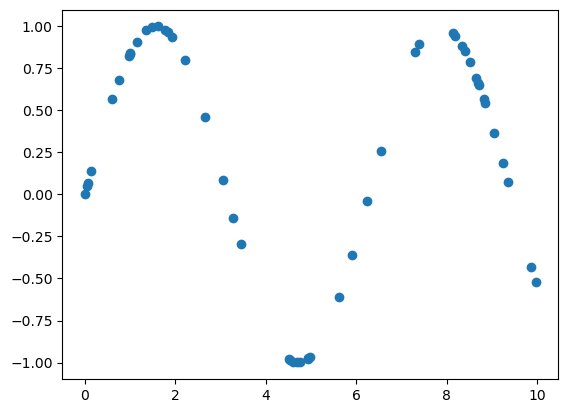

In [3]:
# We then initiate the random values and plot them:
x_sample = np.random.choice(x, sample_size, replace=False)
x_sample = np.sort(x_sample)
y_sample = f(x_sample)
plt.scatter(x_sample, y_sample)

In [4]:
# Evaluation of the random points:
x_evaluate = np.linspace(min(x_sample), max(x_sample), 100)

# Linear
linear_interp = interp1d(x_sample, y_sample, kind="linear") # Outputs a function
linear_result = linear_interp(x_evaluate)                   # So we put the original values to compare

# Nearest
nearest_interp = interp1d(x_sample, y_sample, kind="nearest")
nearest_result = nearest_interp(x_evaluate)

# Quadratic
quadratic_interp = interp1d(x_sample, y_sample, kind="quadratic")
quadratic_result = quadratic_interp(x_evaluate) 

# Cubic
cubic_interp = interp1d(x_sample, y_sample, kind="cubic")
cubic_result = cubic_interp(x_evaluate)

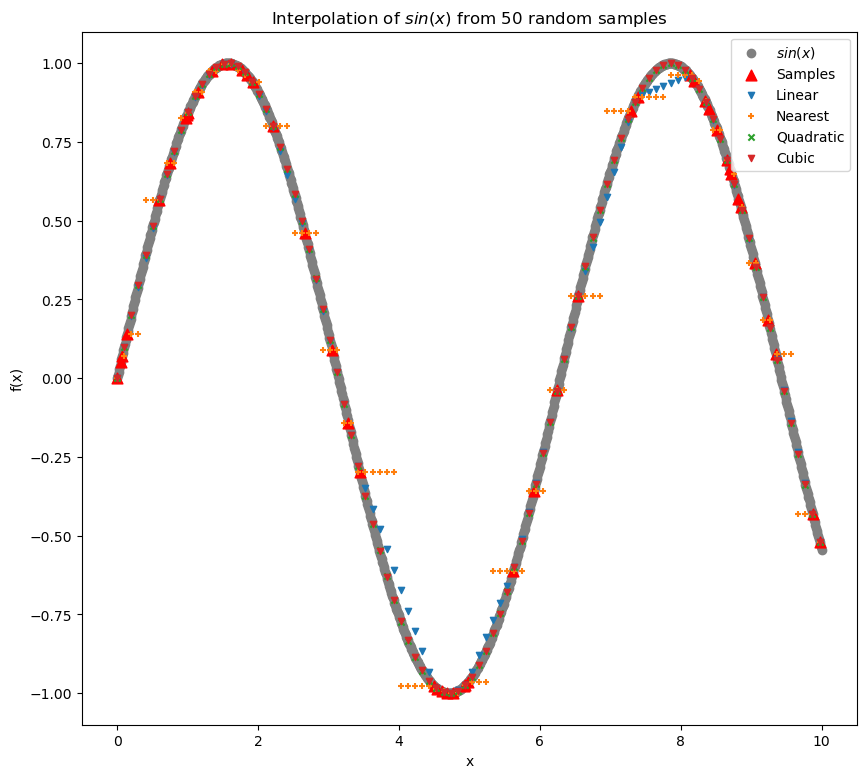

In [5]:
plt.figure(figsize = (10,9))
# The actual function
plt.scatter(x,f(x), color="gray", linewidth=1, label="$sin(x)$")

# The sample
plt.scatter(x_sample,y_sample, marker="^", s=60, color="red", label="Samples")

# For linear 
#linear_output = scipy.interp1d(x_sample,f(x_sample))
plt.scatter(x_evaluate,linear_result, marker="v", s=20, label="Linear")

# For nearest
plt.scatter(x_evaluate,nearest_result, marker="+", s=20, label="Nearest")

# For quadratic
plt.scatter(x_evaluate,quadratic_result, marker="x", s=20, label="Quadratic")

# For cubic interpolations
plt.scatter(x_evaluate,cubic_result, marker="v", s=20, label="Cubic")


plt.title("Interpolation of $sin(x)$ from 50 random samples")
plt.xlabel('x')
plt.ylabel('f(x)')
plt.legend()
# plt.savefig("09_InterpMethods.png")
plt.show()

### Problem 2: Interpolation of real-world data

Load the Dow Jones time-series dataset, randomly retain a specified fraction of observations, and compare the reconstructed curve with the original series. The sampling fractions are 50%, 30%, 10%, and 5%. 

In [6]:
# !wget --quiet https://www-personal.umich.edu/~mejn/cp/data/dow.txt

In [7]:
# load the dataset; download it first if needed
# path is https://websites.umich.edu/~mejn/cp/data/dow.txt

In [8]:
data_DOW = np.loadtxt('data_DOW.txt')
N = len(data_DOW)
x_original = np.arange(N)
print(data_DOW)

[12121.71 12136.44 12226.73 ... 11499.25 11491.91 11478.13]


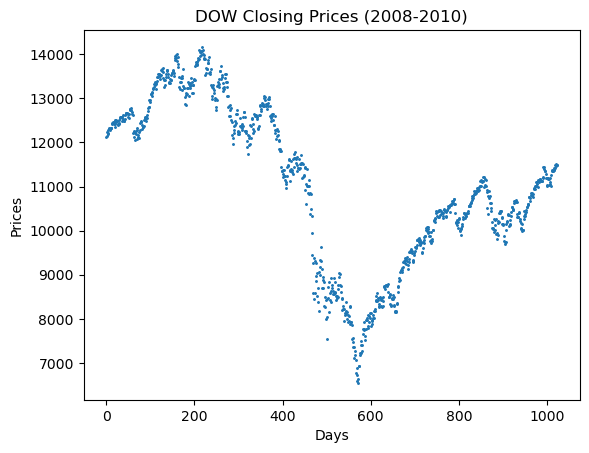

In [9]:
# Plot the data points
# Lengths
x_original = np.arange(0,N)
plt.scatter(x_original,data_DOW, s=1.2)
plt.title("DOW Closing Prices (2008-2010)")
plt.xlabel('Days')
plt.ylabel('Prices')
plt.show()

In [10]:
# Initializing the sample sizes. 
n_50 = int(0.50 * N)
n_30 = int(0.30 * N)
n_10 = int(0.10 * N)
n_05 = int(0.05 * N)

idx_50 = np.sort(rng.choice(N, size=n_50, replace = False))
idx_30 = np.sort(rng.choice(N, size=n_30, replace = False))
idx_10 = np.sort(rng.choice(N, size=n_10, replace = False))
idx_05 = np.sort(rng.choice(N, size=n_05, replace = False))

idx_50[0], idx_50[-1] = 0, N-1
idx_30[0], idx_30[-1] = 0, N-1
idx_10[0], idx_10[-1] = 0, N-1
idx_05[0], idx_05[-1] = 0, N-1

x_50, y_50 = x_original[idx_50], data_DOW[idx_50]
x_30, y_30 = x_original[idx_30], data_DOW[idx_30]
x_10, y_10 = x_original[idx_10], data_DOW[idx_10]
x_05, y_05 = x_original[idx_05], data_DOW[idx_05]

In [11]:
print(f"Total days: {N}")
print(f"50%: {len(x_50)} points | 30%: {len(x_30)} | 10%: {len(x_10)} | 5%: {len(x_05)}")
print("First 10 sample DAYS at 10%:", x_10[:10])

Total days: 1024
50%: 512 points | 30%: 307 | 10%: 102 | 5%: 51
First 10 sample DAYS at 10%: [  0   8  26  32  42  73  78  94 102 111]


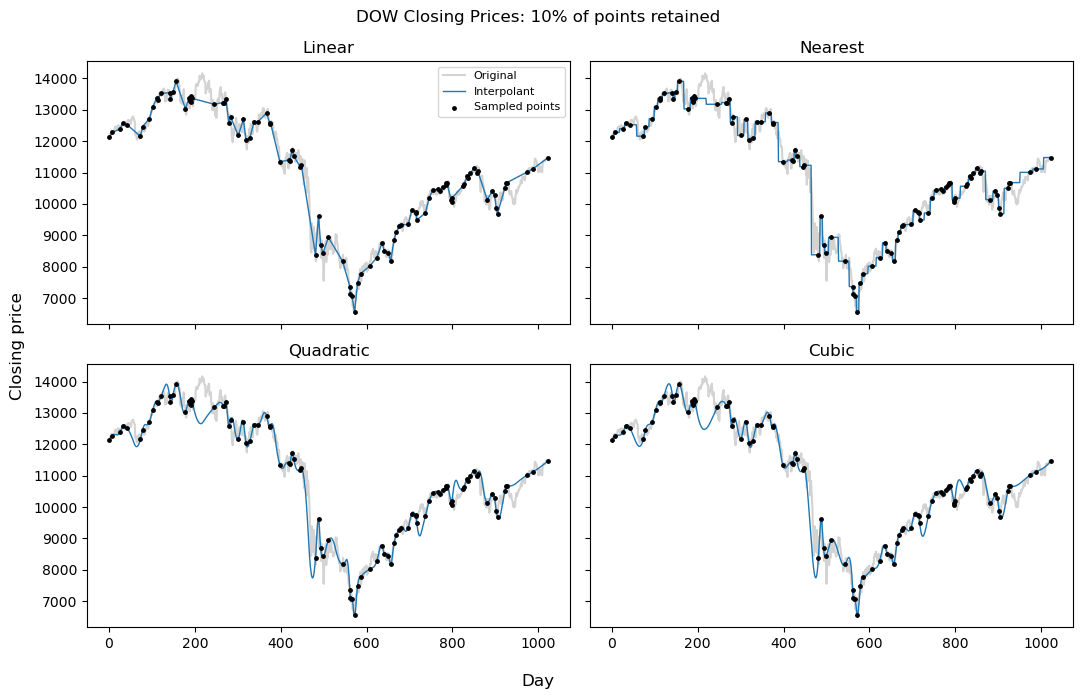

In [12]:
# Build each interpolant from the 10% sample, then evaluate it on every original day
f_linear = interp1d(x_10, y_10, kind='linear')  
y_linear = f_linear(x_original)   

f_nearest = interp1d(x_10, y_10, kind='nearest')
y_nearest = f_nearest(x_original)

f_quadratic = interp1d(x_10, y_10, kind='quadratic')
y_quadratic = f_quadratic(x_original)

f_cubic = interp1d(x_10, y_10, kind='cubic')
y_cubic = f_cubic(x_original)

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, sharey=True)

axes[0, 0].plot(x_original, data_DOW, color='lightgray', label='Original')
axes[0, 0].plot(x_original, y_linear, lw=1, label='Interpolant')
axes[0, 0].scatter(x_10, y_10, s=6, color='k', zorder=3, label='Sampled points')
axes[0, 0].set_title('Linear')

axes[0, 1].plot(x_original, data_DOW, color='lightgray')
axes[0, 1].plot(x_original, y_nearest, lw=1)
axes[0, 1].scatter(x_10, y_10, s=6, color='k', zorder=3)
axes[0, 1].set_title('Nearest')

axes[1, 0].plot(x_original, data_DOW, color='lightgray')
axes[1, 0].plot(x_original, y_quadratic, lw=1)
axes[1, 0].scatter(x_10, y_10, s=6, color='k', zorder=3)
axes[1, 0].set_title('Quadratic')

axes[1, 1].plot(x_original, data_DOW, color='lightgray')
axes[1, 1].plot(x_original, y_cubic, lw=1)
axes[1, 1].scatter(x_10, y_10, s=6, color='k', zorder=3)
axes[1, 1].set_title('Cubic')

axes[0, 0].legend(fontsize=8)
fig.supxlabel('Day')
fig.supylabel('Closing price')
fig.suptitle('DOW Closing Prices: 10% of points retained')
fig.tight_layout()
# plt.savefig("09_ConstantSampling_FourMethods")
plt.show()

In [13]:
# We now zip the data together so they form tuples
# data_tuple = list(zip(x_original, data_DOW))
# a = len(data_DOW)
# x_sample = np.random.choice(data_tuple, size = 512, replace = False)

### Problem 3: Compare interpolation methods on the sampled real-world data

Use a single sampling fraction to compare linear, quadratic, and cubic interpolation. Higher-order interpolation can produce smoother curves, but it can also overshoot between sparse or rapidly changing observations.

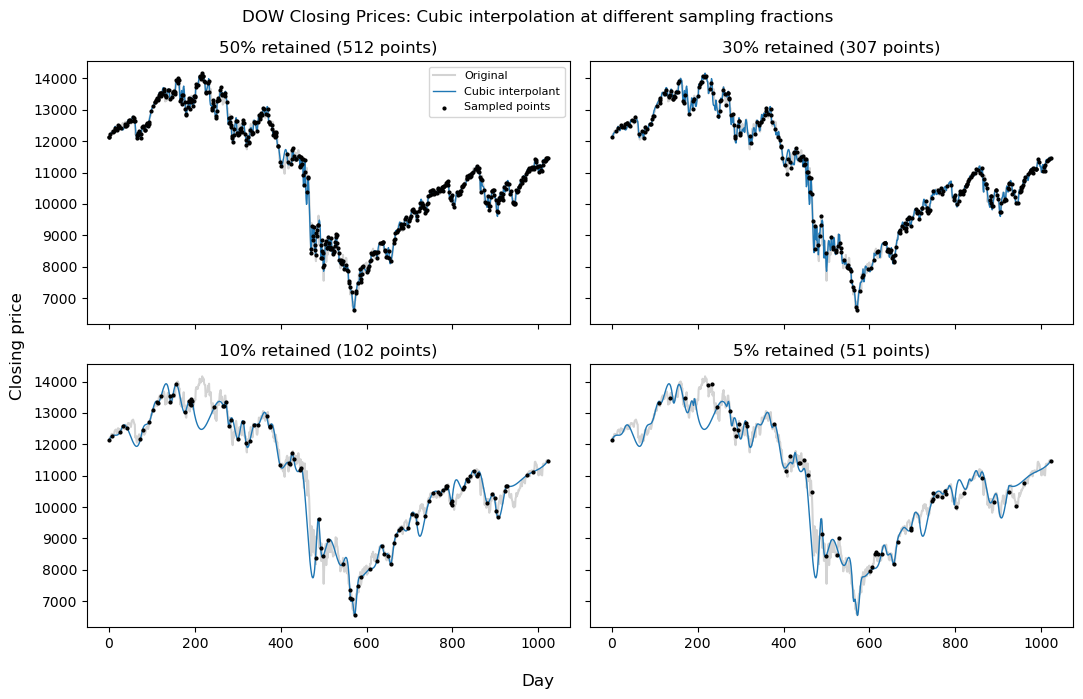

In [14]:
# Build a cubic interpolant from each sample, then evaluate it on every original day
f_cubic_50 = interp1d(x_50, y_50, kind='cubic')  
y_cubic_50 = f_cubic_50(x_original)   

f_cubic_30 = interp1d(x_30, y_30, kind='cubic')  
y_cubic_30 = f_cubic_50(x_original)

f_cubic_10 = interp1d(x_10, y_10, kind='cubic')  
y_cubic_10 = f_cubic_10(x_original)

f_cubic_05 = interp1d(x_05, y_05, kind='cubic')  
y_cubic_05 = f_cubic_10(x_original)

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, sharey=True)

axes[0, 0].plot(x_original, data_DOW, color='lightgray', label='Original')
axes[0, 0].plot(x_original, y_cubic_50, lw=1, label='Cubic interpolant')
axes[0, 0].scatter(x_50, y_50, s=4, color='k', zorder=3, label='Sampled points')
axes[0, 0].set_title(f'50% retained ({len(x_50)} points)')

axes[0, 1].plot(x_original, data_DOW, color='lightgray')
axes[0, 1].plot(x_original, y_cubic_30, lw=1)
axes[0, 1].scatter(x_30, y_30, s=4, color='k', zorder=3)
axes[0, 1].set_title(f'30% retained ({len(x_30)} points)')

axes[1, 0].plot(x_original, data_DOW, color='lightgray')
axes[1, 0].plot(x_original, y_cubic_10, lw=1)
axes[1, 0].scatter(x_10, y_10, s=4, color='k', zorder=3)
axes[1, 0].set_title(f'10% retained ({len(x_10)} points)')

axes[1, 1].plot(x_original, data_DOW, color='lightgray')
axes[1, 1].plot(x_original, y_cubic_05, lw=1)
axes[1, 1].scatter(x_05, y_05, s=4, color='k', zorder=3)
axes[1, 1].set_title(f'5% retained ({len(x_05)} points)')

axes[0, 0].legend(fontsize=8)
fig.supxlabel('Day')
fig.supylabel('Closing price')
fig.suptitle('DOW Closing Prices: Cubic interpolation at different sampling fractions')
fig.tight_layout()
# plt.savefig("09_ConstantNearest_FourSampling")
plt.show()

### Problem  code summary

First, the code draws 50 random, sorted samples from sin(x) on [0, 10] and reconstructs the function inside the sampled range using SciPy’s interp1d with nearest, linear, quadratic, and cubic interpolation. Then, two figures compare the reconstructions with the original: one applies the four methods (linear, nearest, quadratic, cubic) to the 10% sample to the DOW Jones data, and the other applies nearest neighbor interpolation across all four sampling fractions.

---